**1. Data Cleaning**

In [2]:
import pandas as pd
import numpy as np
from google.colab import files
import os

# Prompt to upload 'ted_talks_en.csv' if it's not already in the current directory
try:
    # Try reading the original file with on_bad_lines='skip' to bypass parsing errors on malformed rows
    df = pd.read_csv("ted_talks_en.csv", on_bad_lines="skip")
except (FileNotFoundError, pd.errors.ParserError):
    print("Please upload 'ted_talks_en.csv' below:")
    uploaded = files.upload()
    # Retrieve the actual filename uploaded (to handle 'ted_talks_en (1).csv' correctly)
    uploaded_filename = list(uploaded.keys())[0]
    df = pd.read_csv(uploaded_filename, on_bad_lines="skip")

print("Original Shape:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Remove duplicate talk IDs
if "talk_id" in df.columns:
    df = df.drop_duplicates(subset="talk_id")

# Check missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# Fill numerical missing values
if "comments" in df.columns:
    df["comments"] = df["comments"].fillna(df["comments"].median())

# Fill text missing values
text_columns = [
    "title",
    "speaker_1",
    "all_speakers",
    "occupations",
    "about_speakers",
    "description",
    "transcript"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

# Fill other columns
for col in ["topics", "related_talks", "available_lang"]:
    if col in df.columns:
        df[col] = df[col].fillna("[]")

# Remove rows with missing/empty titles
if "title" in df.columns:
    df = df[
        df["title"].notna() &
        (df["title"].str.strip() != "")
    ]

# Reset index
df = df.reset_index(drop=True)

print("\nShape After Cleaning:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Please upload 'ted_talks_en.csv' below:


Saving ted_talks_en.csv to ted_talks_en (2).csv
Original Shape: (4005, 19)

Missing Values Before Cleaning:
talk_id             0
title               0
speaker_1           0
all_speakers        4
occupations       522
about_speakers    503
views               0
recorded_date       1
published_date      0
event               0
native_lang         0
available_lang      0
comments          655
duration            0
topics              0
related_talks       0
url                 0
description         0
transcript          0
dtype: int64

Shape After Cleaning: (4005, 19)

Missing Values After Cleaning:
talk_id           0
title             0
speaker_1         0
all_speakers      0
occupations       0
about_speakers    0
views             0
recorded_date     1
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
dtype: int64


**2. Preprocessing**

In [3]:

import re
import string
import ast

# Convert dates
df["recorded_date"] = pd.to_datetime(
    df["recorded_date"],
    errors="coerce"
)

df["published_date"] = pd.to_datetime(
    df["published_date"],
    errors="coerce"
)


# Text cleaning function
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove HTML
    text = re.sub(r"<.*?>", "", text)

    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Text columns to preprocess
text_columns = [
    "title",
    "speaker_1",
    "occupations",
    "about_speakers",
    "description",
    "transcript"
]

for col in text_columns:
    df[col] = df[col].apply(clean_text)


# Convert list/dictionary-like columns to text
def convert_to_text(value):

    try:
        value = ast.literal_eval(str(value))

        if isinstance(value, list):
            return " ".join(map(str, value))

        elif isinstance(value, dict):
            return " ".join(map(str, value.values()))

        return str(value)

    except:
        return str(value)


for col in ["topics", "all_speakers"]:
    df[col] = df[col].apply(convert_to_text)


# Create useful numerical features
df["duration_minutes"] = df["duration"] / 60

df["log_views"] = np.log1p(df["views"])

df["log_comments"] = np.log1p(df["comments"])

# Extract year
df["recorded_year"] = df["recorded_date"].dt.year
df["published_year"] = df["published_date"].dt.year


print("Preprocessing completed successfully!")

display(df.head())

Preprocessing completed successfully!


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,topics,related_talks,url,description,transcript,duration_minutes,log_views,log_comments,recorded_year,published_year
0,1,averting the climate crisis,al gore,Al Gore,climate advocate,nobel laureate al gore focused the world’s att...,3523392,2006-02-25,2006-06-27,TED2006,...,alternative energy cars climate change culture...,"{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,with the same humor and humanity he exuded in ...,thank you so much chris and its truly a great ...,16.283333,15.074935,5.609472,2006.0,2006
1,92,the best stats youve ever seen,hans rosling,Hans Rosling,global health expert data visionary,in hans rosling’s hands data sings global tren...,14501685,2006-02-22,2006-06-27,TED2006,...,Africa Asia Google demo economics global issue...,"{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,youve never seen data presented like this with...,about years ago i took on the task to teach gl...,19.833333,16.489775,6.444131,2006.0,2006
2,7,simplicity sells,david pogue,David Pogue,technology columnist,david pogue is the personal technology columni...,1920832,2006-02-24,2006-06-27,TED2006,...,computers entertainment interface design media...,"{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,new york times columnist david pogue takes aim...,music the sound of silence simon garfunkel hel...,21.433333,14.468270,4.828314,2006.0,2006
3,53,greening the ghetto,majora carter,Majora Carter,activist for environmental justice,majora carter redefined the field of environme...,2664069,2006-02-26,2006-06-27,TED2006,...,MacArthur grant activism business cities envir...,{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,in an emotionally charged talk macarthurwinnin...,if youre here today — and im very happy that y...,18.600000,14.795366,5.393628,2006.0,2006
4,66,do schools kill creativity,sir ken robinson,Sir Ken Robinson,author educator,creativity expert sir ken robinson challenges ...,65051954,2006-02-25,2006-06-27,TED2006,...,children creativity culture dance education pa...,"{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,sir ken robinson makes an entertaining and pro...,good morning how are you audience good its bee...,19.400000,17.990697,8.503500,2006.0,2006


**3. EDA**

Dataset Shape: (4005, 24)

Statistical Summary:


,views,comments,duration,duration_minutes
count,4.005000e+03,4005.000000,4005.000000,4005.000000
mean,2.148006e+06,150.058677,724.011236,12.066854
std,3.451226e+06,247.346686,361.775462,6.029591
min,0.000000e+00,0.000000,60.000000,1.000000
25%,8.820690e+05,46.000000,393.000000,6.550000
50%,1.375508e+06,89.000000,738.000000,12.300000
75%,2.133110e+06,162.000000,974.000000,16.233333
max,6.505195e+07,6449.000000,3922.000000,65.366667


,title,speaker_1,views
4,do schools kill creativity,sir ken robinson,65051954
1296,your body language may shape who you are,amy cuddy,57074270
2062,this is what happens when you reply to spam email,james veitch,56932551
646,how great leaders inspire action,simon sinek,49730580
796,the power of vulnerability,brené brown,47544833
1724,how to speak so that people want to listen,julian treasure,41504331
2108,inside the mind of a master procrastinator,tim urban,37976820
1366,looks arent everything believe me im a model,cameron russell,33874546
2724,my philosophy for a happy life,sam berns,33691484
1898,the next outbreak were not ready,bill gates,33521780


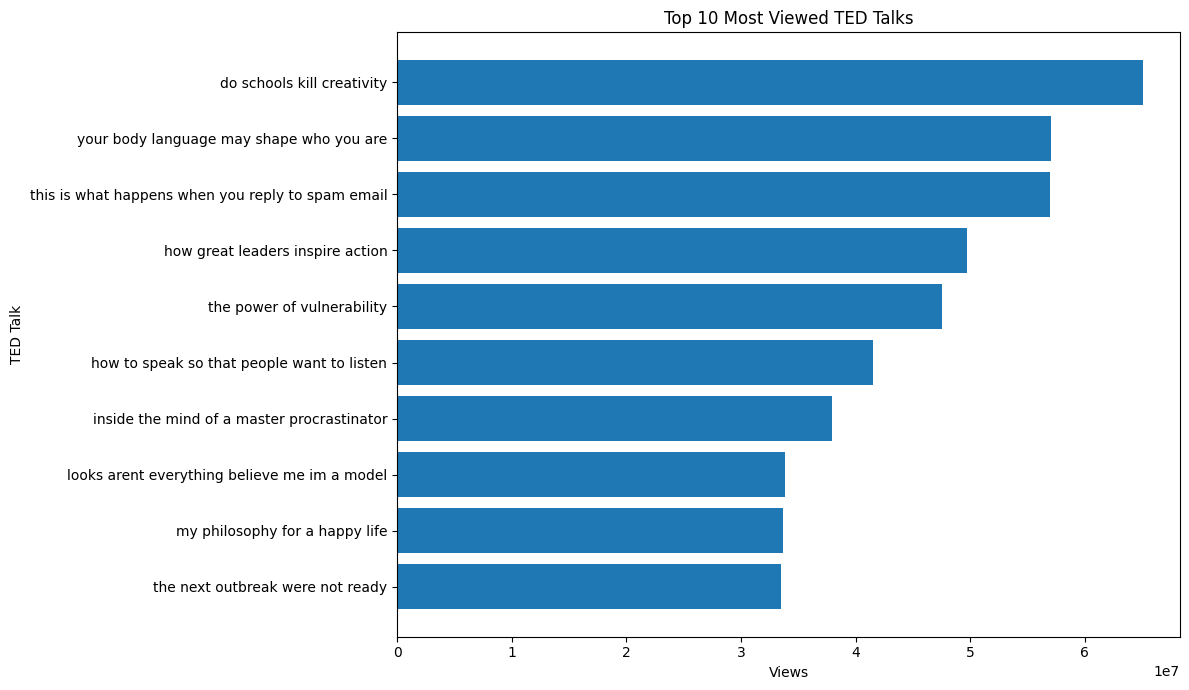

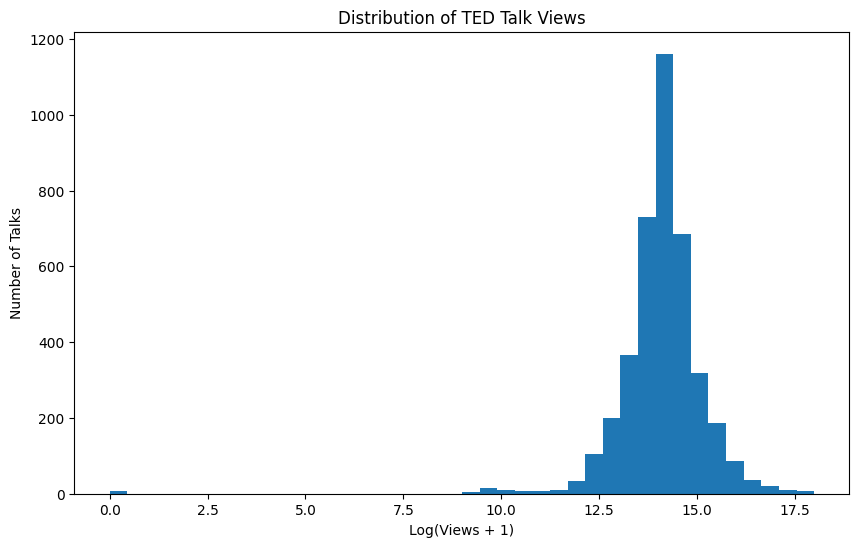

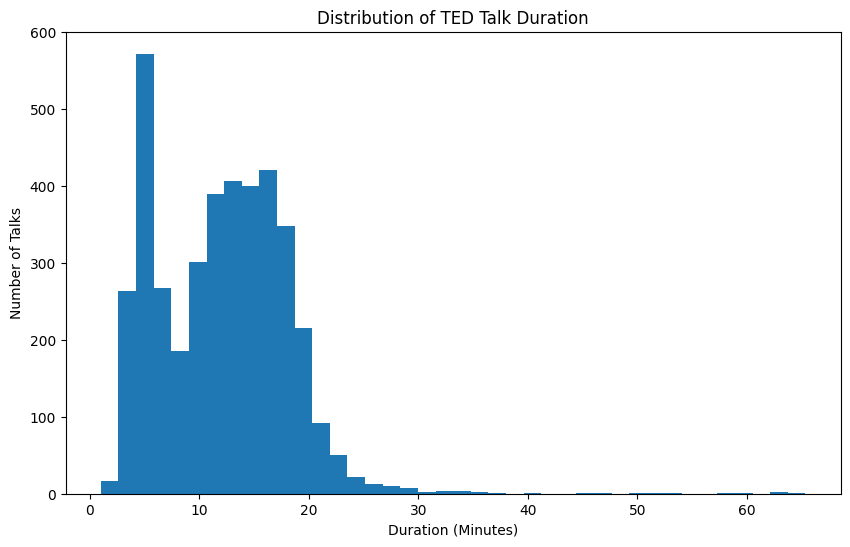

,count
speaker_1,
alex gendler,34
iseult gillespie,19
emma bryce,12
daniel finkel,11
alex rosenthal,10
hans rosling,10
greg gage,9
juan enriquez,9
chris anderson,8


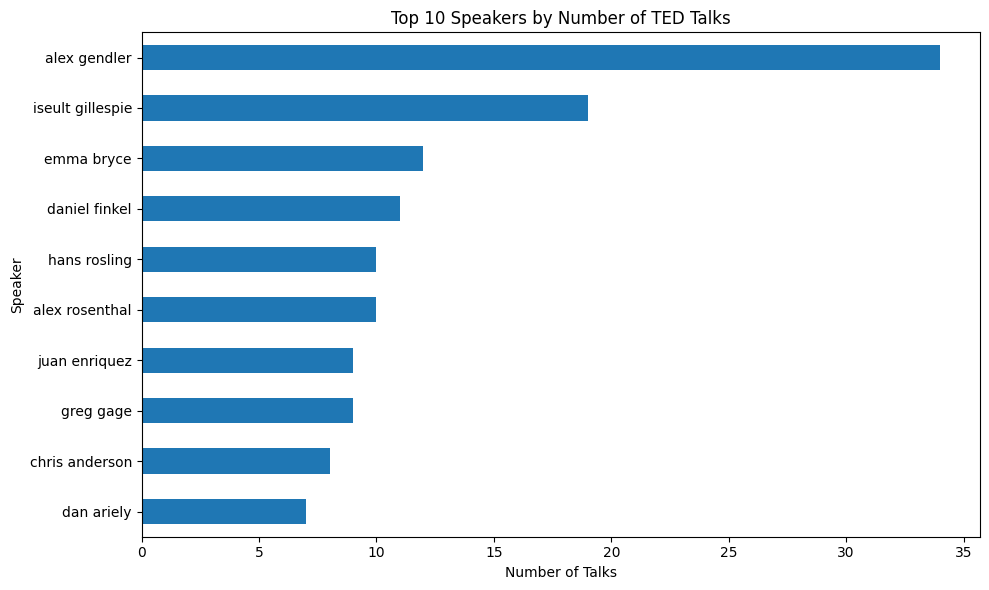

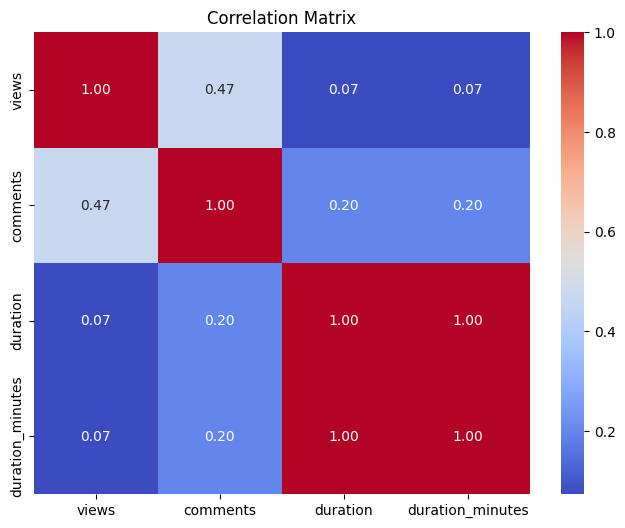

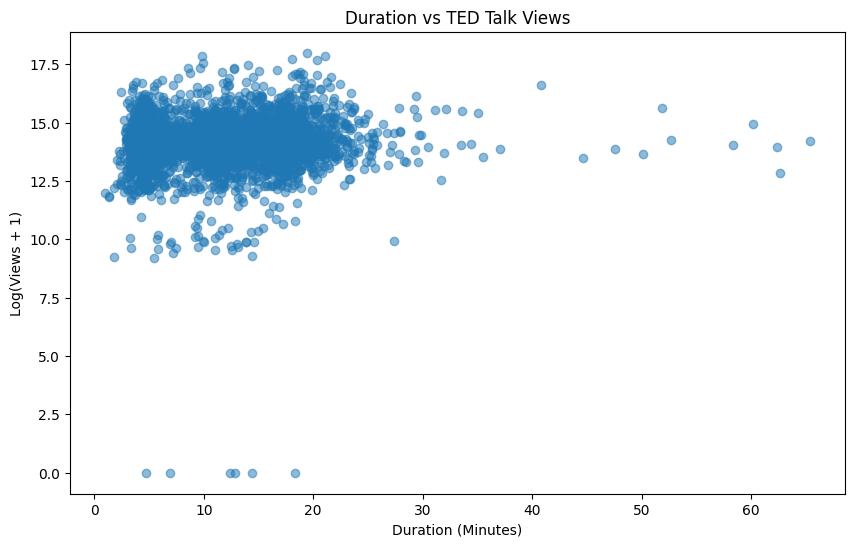

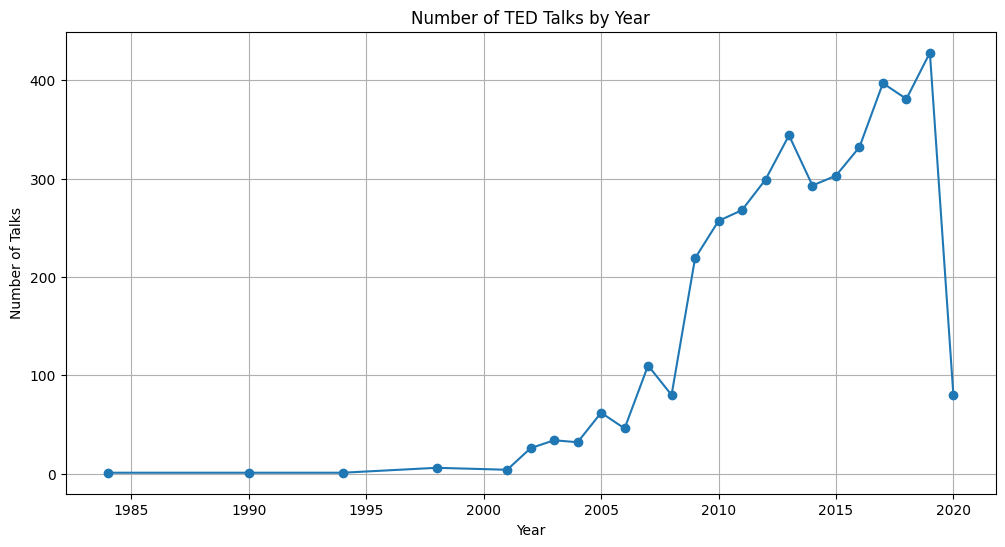

========== EDA SUMMARY ==========
Total Talks: 4005
Unique Speakers: 3274
Unique Events: 459
Average Views: 2148005.57
Median Views: 1375508.0
Average Duration: 12.07 minutes


In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Basic information
print("Dataset Shape:", df.shape)

print("\nStatistical Summary:")
display(
    df[
        [
            "views",
            "comments",
            "duration",
            "duration_minutes"
        ]
    ].describe()
)

# 1. Top 10 Most Viewed TED Talks


top_talks = df.nlargest(10, "views")

display(
    top_talks[
        [
            "title",
            "speaker_1",
            "views"
        ]
    ]
)


plt.figure(figsize=(12, 7))

plot_data = top_talks.sort_values("views")

plt.barh(
    plot_data["title"],
    plot_data["views"]
)

plt.xlabel("Views")
plt.ylabel("TED Talk")
plt.title("Top 10 Most Viewed TED Talks")

plt.tight_layout()
plt.show()


# 2. Distribution of Views

plt.figure(figsize=(10, 6))

plt.hist(
    df["log_views"],
    bins=40
)

plt.xlabel("Log(Views + 1)")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Views")

plt.show()


# 3. Duration Distribution

plt.figure(figsize=(10, 6))

plt.hist(
    df["duration_minutes"],
    bins=40
)

plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Duration")

plt.show()


# 4. Top 10 Speakers

top_speakers = df["speaker_1"].value_counts().head(10)

display(top_speakers)


plt.figure(figsize=(10, 6))

top_speakers.sort_values().plot(kind="barh")

plt.xlabel("Number of Talks")
plt.ylabel("Speaker")
plt.title("Top 10 Speakers by Number of TED Talks")

plt.tight_layout()
plt.show()


# 5. Correlation Analysis

numeric_columns = [
    "views",
    "comments",
    "duration",
    "duration_minutes"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()


# 6. Duration vs Views

plt.figure(figsize=(10, 6))

plt.scatter(
    df["duration_minutes"],
    df["log_views"],
    alpha=0.5
)

plt.xlabel("Duration (Minutes)")
plt.ylabel("Log(Views + 1)")
plt.title("Duration vs TED Talk Views")

plt.show()


# 7. Year-wise TED Talks

yearly_talks = (
    df["recorded_year"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_talks.index,
    yearly_talks.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of Talks")
plt.title("Number of TED Talks by Year")

plt.grid(True)
plt.show()


# FINAL EDA SUMMARY

print("========== EDA SUMMARY ==========")
print("Total Talks:", len(df))
print("Unique Speakers:", df["speaker_1"].nunique())
print("Unique Events:", df["event"].nunique())
print("Average Views:", round(df["views"].mean(), 2))
print("Median Views:", round(df["views"].median(), 2))
print(
    "Average Duration:",
    round(df["duration_minutes"].mean(), 2),
    "minutes"
)

Top 15 Topics:


,Topic,Count
0,science,1129
1,technology,979
2,health,943
3,change,684
4,culture,680
5,global,669
6,design,651
7,social,594
8,TEDx,581
9,issues,574



Topic count per talk:


,title,topic_count
0,averting the climate crisis,12
1,the best stats youve ever seen,13
2,simplicity sells,10
3,greening the ghetto,10
4,do schools kill creativity,7


<Figure size 1000x600 with 0 Axes>

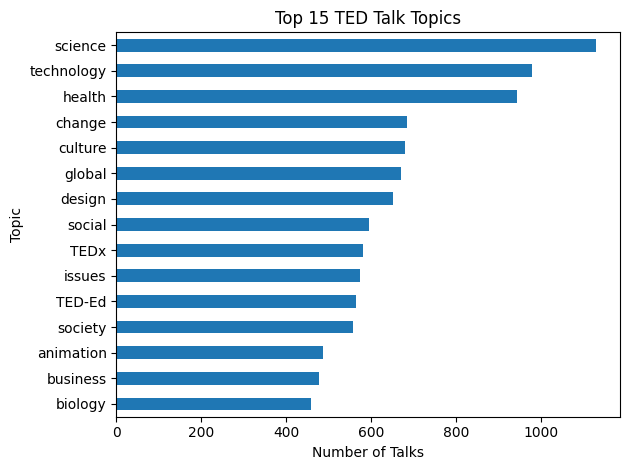

In [5]:
# TOPIC ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import ast

def extract_list(value):
    try:
        value = ast.literal_eval(str(value))
        if isinstance(value, list):
            return value
    except:
        pass

    # Handle already converted text
    return str(value).split()

# Extract topics
all_topics = []

for value in df["topics"]:
    topics = extract_list(value)
    all_topics.extend(topics)

topic_counts = Counter(all_topics)

top_topics = pd.DataFrame(
    topic_counts.most_common(15),
    columns=["Topic", "Count"]
)

print("Top 15 Topics:")
display(top_topics)

# Number of topics per talk
df["topic_count"] = df["topics"].apply(
    lambda x: len(extract_list(x))
)

print("\nTopic count per talk:")
display(df[["title", "topic_count"]].head())


# Visualization
plt.figure(figsize=(10, 6))

top_topics.sort_values("Count").plot(
    x="Topic",
    y="Count",
    kind="barh",
    legend=False
)

plt.xlabel("Number of Talks")
plt.ylabel("Topic")
plt.title("Top 15 TED Talk Topics")

plt.tight_layout()
plt.show()

Unique speakers using speaker_1: 3274
Unique speakers using all_speakers: 4619

Speakers with multiple talks:


,count
speaker_1,
alex gendler,34
iseult gillespie,19
emma bryce,12
daniel finkel,11
alex rosenthal,10
hans rosling,10
greg gage,9
juan enriquez,9
chris anderson,8


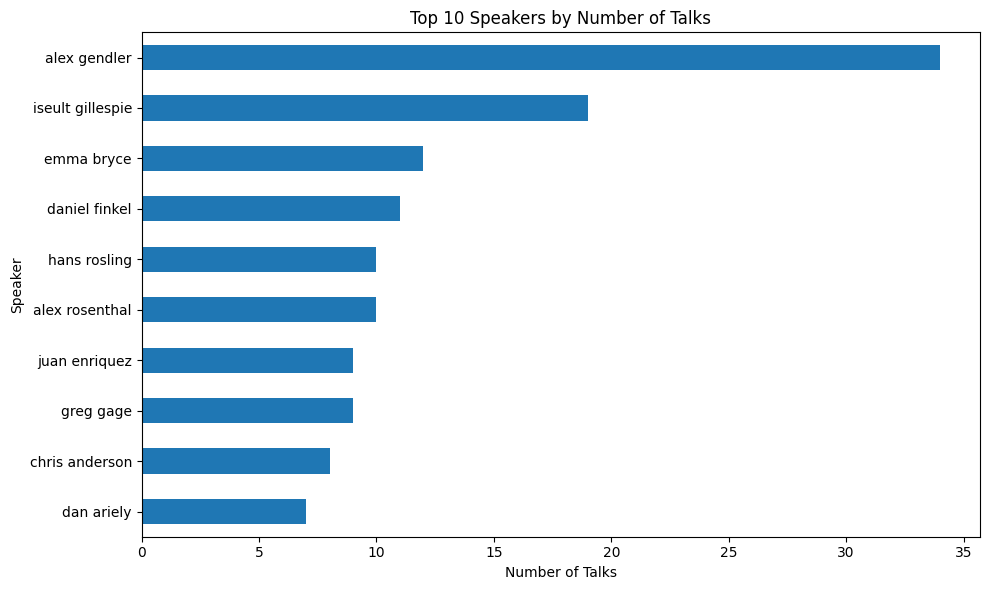

In [6]:
# SPEAKER ANALYSIS

# Unique speakers using speaker_1
unique_speaker_1 = df["speaker_1"].nunique()

print("Unique speakers using speaker_1:",
      unique_speaker_1)


# Extract all speakers
all_speakers = []

for value in df["all_speakers"]:
    speakers = extract_list(value)
    all_speakers.extend(speakers)

unique_all_speakers = len(set(all_speakers))

print("Unique speakers using all_speakers:",
      unique_all_speakers)


# Speakers with multiple talks
speaker_counts = df["speaker_1"].value_counts()

multiple_talk_speakers = speaker_counts[
    speaker_counts > 1
]

print("\nSpeakers with multiple talks:")
display(multiple_talk_speakers.head(20))


# Top 10 speakers
top_10_speakers = speaker_counts.head(10)

plt.figure(figsize=(10, 6))

top_10_speakers.sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of Talks")
plt.ylabel("Speaker")
plt.title("Top 10 Speakers by Number of Talks")

plt.tight_layout()
plt.show()

In [7]:
# TEXT ANALYSIS

# Word count function
def word_count(text):
    return len(str(text).split())


# Calculate word counts
df["title_word_count"] = df["title"].apply(word_count)

df["description_word_count"] = df["description"].apply(word_count)

df["transcript_word_count"] = df["transcript"].apply(word_count)

df["about_speaker_word_count"] = df["about_speakers"].apply(word_count)


# Display word count statistics
text_stats = df[
    [
        "title_word_count",
        "description_word_count",
        "transcript_word_count",
        "about_speaker_word_count"
    ]
].describe()

display(text_stats)


# Empty text entries
print("Empty Titles:",
      (df["title"].str.strip() == "").sum())

print("Empty Descriptions:",
      (df["description"].str.strip() == "").sum())

print("Empty Transcripts:",
      (df["transcript"].str.strip() == "").sum())


# Very short transcripts
short_transcripts = df[
    df["transcript_word_count"] < 50
]

print("\nVery short transcripts (<50 words):",
      len(short_transcripts))


# Very long transcripts
long_transcripts = df[
    df["transcript_word_count"] > 5000
]

print("Very long transcripts (>5000 words):",
      len(long_transcripts))


# Transcript quality
print("\nTranscript usability:")
print(
    "Usable transcripts:",
    (df["transcript_word_count"] >= 50).sum()
)

print(
    "Very short transcripts:",
    (df["transcript_word_count"] < 50).sum()
)

,title_word_count,description_word_count,transcript_word_count,about_speaker_word_count
count,4005.000000,4005.000000,4005.000000,4005.000000
mean,6.636454,57.263670,1786.237203,21.275905
std,2.367502,19.217819,998.653985,15.480097
min,1.000000,9.000000,2.000000,1.000000
25%,5.000000,42.000000,916.000000,14.000000
50%,6.000000,56.000000,1743.000000,20.000000
75%,8.000000,71.000000,2430.000000,27.000000
max,16.000000,140.000000,11080.000000,233.000000


Empty Titles: 0
Empty Descriptions: 0
Empty Transcripts: 0

Very short transcripts (<50 words): 10
Very long transcripts (>5000 words): 21

Transcript usability:
Usable transcripts: 3995
Very short transcripts: 10


Mean Views: 2148005.5737827714
Median Views: 1375508.0
Minimum Views: 0
Maximum Views: 65051954

Top 10 Most Viewed TED Talks:


,title,speaker_1,views
4,do schools kill creativity,sir ken robinson,65051954
1296,your body language may shape who you are,amy cuddy,57074270
2062,this is what happens when you reply to spam email,james veitch,56932551
646,how great leaders inspire action,simon sinek,49730580
796,the power of vulnerability,brené brown,47544833
1724,how to speak so that people want to listen,julian treasure,41504331
2108,inside the mind of a master procrastinator,tim urban,37976820
1366,looks arent everything believe me im a model,cameron russell,33874546
2724,my philosophy for a happy life,sam berns,33691484
1898,the next outbreak were not ready,bill gates,33521780


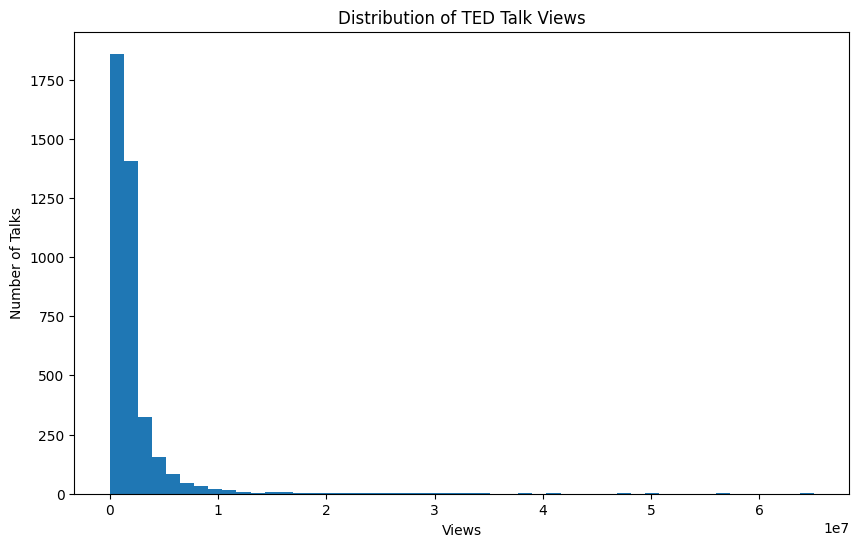

Potential view outliers: 393


In [8]:
# VIEWS ANALYSIS

print("Mean Views:", df["views"].mean())
print("Median Views:", df["views"].median())
print("Minimum Views:", df["views"].min())
print("Maximum Views:", df["views"].max())


# Top 10 most viewed talks
top_views = df.nlargest(10, "views")

print("\nTop 10 Most Viewed TED Talks:")
display(
    top_views[
        ["title", "speaker_1", "views"]
    ]
)


# Histogram
plt.figure(figsize=(10, 6))

plt.hist(df["views"], bins=50)

plt.xlabel("Views")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Views")

plt.show()


# IQR outlier detection
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

view_outliers = df[
    (df["views"] < lower) |
    (df["views"] > upper)
]

print("Potential view outliers:",
      len(view_outliers))

Average Duration: 724.0112359550562 seconds
Median Duration: 738.0 seconds
Minimum Duration: 60 seconds
Maximum Duration: 3922 seconds

Invalid duration values: 0


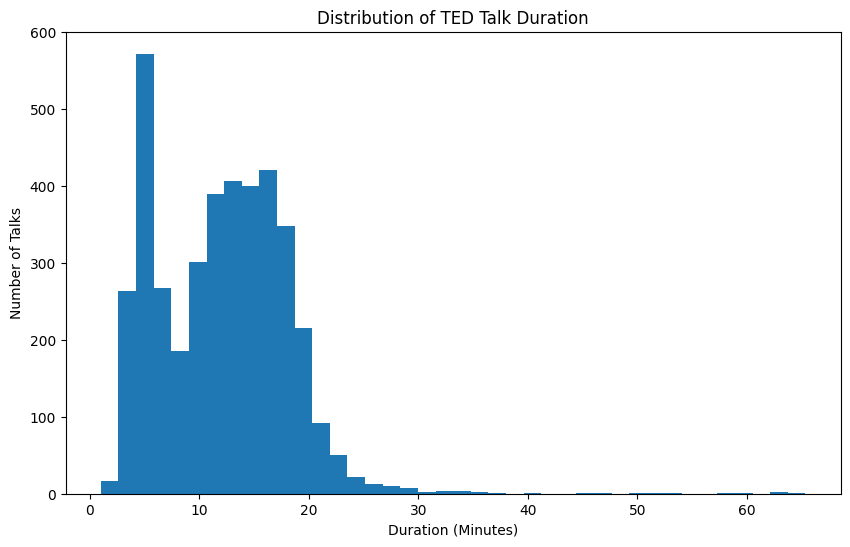

In [9]:
# DURATION ANALYSIS

print("Average Duration:",
      df["duration"].mean(), "seconds")

print("Median Duration:",
      df["duration"].median(), "seconds")

print("Minimum Duration:",
      df["duration"].min(), "seconds")

print("Maximum Duration:",
      df["duration"].max(), "seconds")


# Invalid duration values
invalid_duration = df[
    df["duration"].isna() |
    (df["duration"] <= 0)
]

print("\nInvalid duration values:",
      len(invalid_duration))


# Duration histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df["duration_minutes"],
    bins=40
)

plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Duration")

plt.show()

Earliest Publication Date: 2006-06-27 00:00:00
Latest Publication Date: 2020-04-30 00:00:00


,count
publication_year,
2006,49
2007,119
2008,185
2009,215
2010,230
2011,255
2012,303
2013,242
2014,240


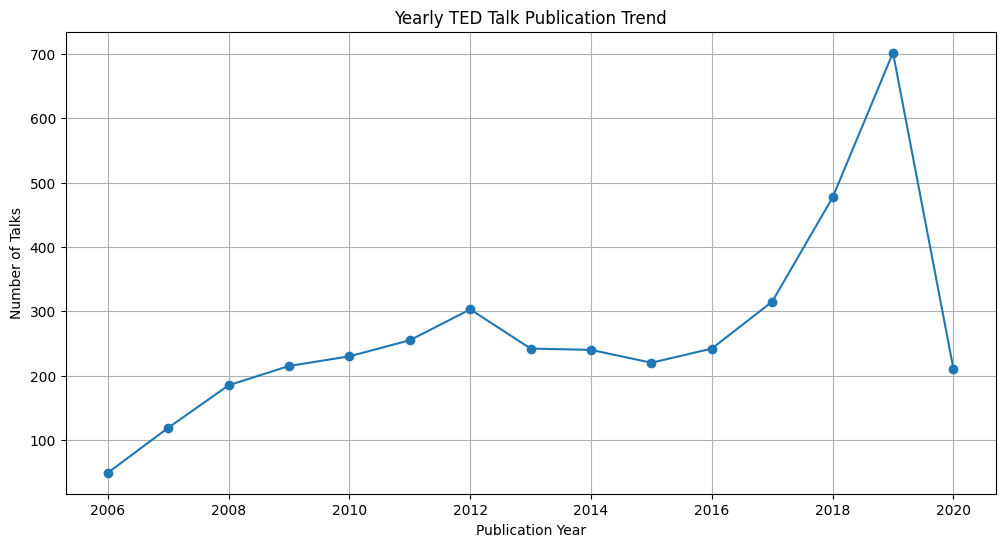

In [10]:
# DATE ANALYSIS

df["recorded_date"] = pd.to_datetime(
    df["recorded_date"],
    errors="coerce"
)

df["published_date"] = pd.to_datetime(
    df["published_date"],
    errors="coerce"
)


print("Earliest Publication Date:",
      df["published_date"].min())

print("Latest Publication Date:",
      df["published_date"].max())


# Talks published per year
df["publication_year"] = (
    df["published_date"].dt.year
)

yearly_publications = (
    df["publication_year"]
    .value_counts()
    .sort_index()
)

display(yearly_publications)


# Yearly trend
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_publications.index,
    yearly_publications.values,
    marker="o"
)

plt.xlabel("Publication Year")
plt.ylabel("Number of Talks")
plt.title("Yearly TED Talk Publication Trend")

plt.grid(True)
plt.show()

Top Native Languages:


,count
native_lang,
en,3957
es,27
fr,9
ja,3
hi,2
de,1
pt,1
ko,1
pt-br,1



Available Language Analysis:


,Language,Count
0,en,4005
1,es,3915
2,pt-br,3899
3,fr,3863
4,ar,3841
5,zh-tw,3818
6,zh-cn,3788
7,ko,3755
8,ru,3676
9,tr,3610


Missing Native Language: 0
Missing Available Language: 0


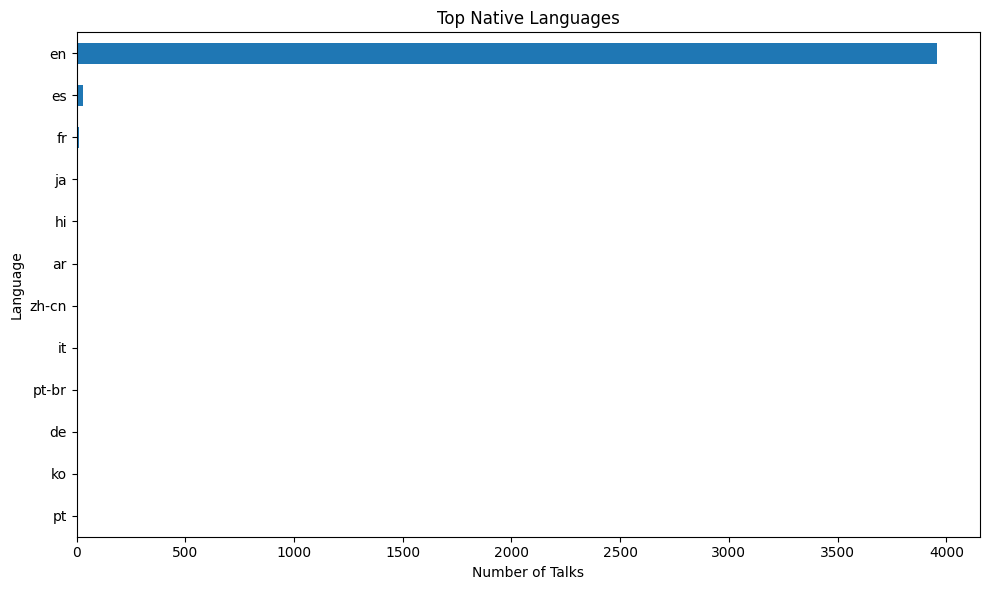

In [11]:
# LANGUAGE ANALYSIS

print("Top Native Languages:")

native_languages = (
    df["native_lang"]
    .value_counts()
    .head(15)
)

display(native_languages)


# Available languages
print("\nAvailable Language Analysis:")

language_values = []

for value in df["available_lang"]:
    languages = extract_list(value)
    language_values.extend(languages)

available_language_counts = Counter(
    language_values
)

available_language_df = pd.DataFrame(
    available_language_counts.most_common(15),
    columns=["Language", "Count"]
)

display(available_language_df)


# Missing values
print(
    "Missing Native Language:",
    df["native_lang"].isna().sum()
)

print(
    "Missing Available Language:",
    df["available_lang"].isna().sum()
)


# Native language visualization
plt.figure(figsize=(10, 6))

native_languages.sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of Talks")
plt.ylabel("Language")
plt.title("Top Native Languages")

plt.tight_layout()
plt.show()

Top 10 Events:


,count
event,
TED-Ed,556
TED2017,96
TED2018,96
TED2019,91
TED2014,84
TED2009,81
TED2016,75
TED2015,75
TED2013,75


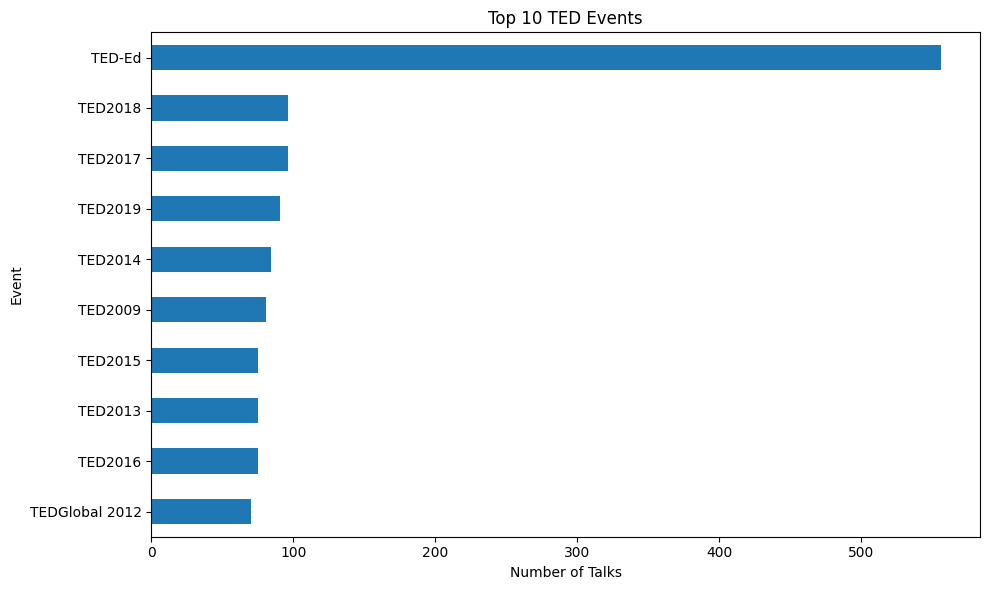


Top Occupations:


,Occupation,Count
0,unknown,522
1,activist,218
2,and,204
3,entrepreneur,191
4,author,175
5,writer,175
6,artist,160
7,designer,143
8,scientist,137
9,expert,120


<Figure size 1000x600 with 0 Axes>

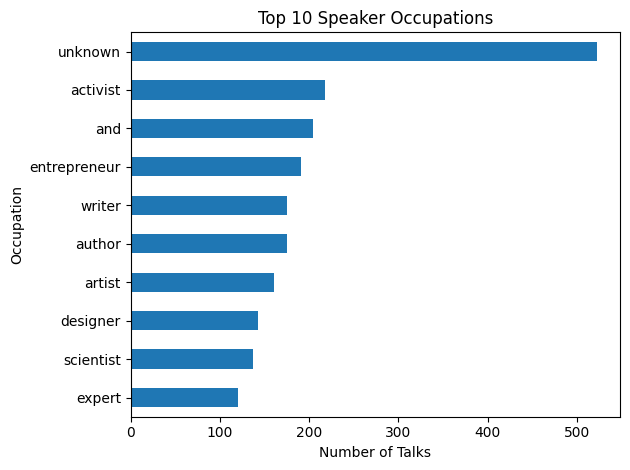

In [12]:
# EVENT AND OCCUPATION ANALYSIS

# Top events
top_events = df["event"].value_counts().head(10)

print("Top 10 Events:")
display(top_events)


plt.figure(figsize=(10, 6))

top_events.sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of Talks")
plt.ylabel("Event")
plt.title("Top 10 TED Events")

plt.tight_layout()
plt.show()


# Occupations
occupation_values = []

for value in df["occupations"]:
    occupations = extract_list(value)
    occupation_values.extend(occupations)


occupation_counts = Counter(
    occupation_values
)

top_occupations = pd.DataFrame(
    occupation_counts.most_common(10),
    columns=["Occupation", "Count"]
)

print("\nTop Occupations:")
display(top_occupations)


plt.figure(figsize=(10, 6))

top_occupations.sort_values("Count").plot(
    x="Occupation",
    y="Count",
    kind="barh",
    legend=False
)

plt.xlabel("Number of Talks")
plt.ylabel("Occupation")
plt.title("Top 10 Speaker Occupations")

plt.tight_layout()
plt.show()

Mean Comments: 150.05867665418228
Median Comments: 89.0
Minimum Comments: 0.0
Maximum Comments: 6449.0

Top 10 Talks by Comments:


,title,speaker_1,comments
94,militant atheism,richard dawkins,6449.0
4,do schools kill creativity,sir ken robinson,4931.0
617,science can answer moral questions,sam harris,3424.0
1735,how do you explain consciousness,david chalmers,3006.0
197,my stroke of insight,jill bolte taylor,2984.0
1296,your body language may shape who you are,amy cuddy,2633.0
911,taking imagination seriously,janet echelman,2529.0
799,on reading the koran,lesley hazleton,2463.0
631,the danger of science denial,michael specter,2366.0
796,the power of vulnerability,brené brown,2209.0


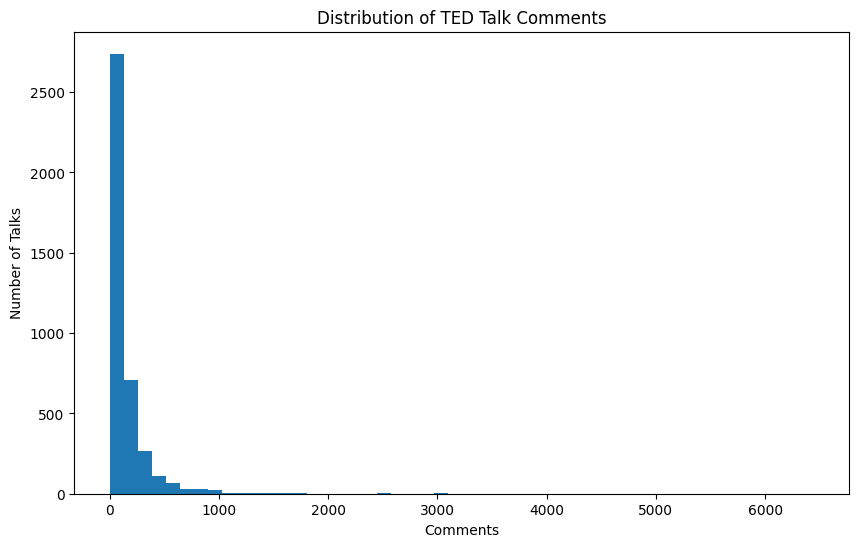

Potential comment outliers: 361


In [13]:
# COMMENTS ANALYSIS

print("Mean Comments:",
      df["comments"].mean())

print("Median Comments:",
      df["comments"].median())

print("Minimum Comments:",
      df["comments"].min())

print("Maximum Comments:",
      df["comments"].max())


# Highest commented talks
top_comments = df.nlargest(10, "comments")

print("\nTop 10 Talks by Comments:")

display(
    top_comments[
        ["title", "speaker_1", "comments"]
    ]
)


# Distribution
plt.figure(figsize=(10, 6))

plt.hist(
    df["comments"],
    bins=50
)

plt.xlabel("Comments")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Comments")

plt.show()


# Outliers
Q1 = df["comments"].quantile(0.25)
Q3 = df["comments"].quantile(0.75)

IQR = Q3 - Q1

upper_comments = Q3 + 1.5 * IQR

comment_outliers = df[
    df["comments"] > upper_comments
]

print(
    "Potential comment outliers:",
    len(comment_outliers)
)

In [14]:
# RELATED TALKS ANALYSIS

def count_related(value):

    try:
        value = ast.literal_eval(str(value))

        if isinstance(value, list):
            return len(value)

    except:
        pass

    return 0


# Count related talks
df["related_talk_count"] = (
    df["related_talks"]
    .apply(count_related)
)

print("Related talks statistics:")

display(
    df["related_talk_count"].describe()
)


# Talks with most related talks
display(
    df[
        [
            "title",
            "related_talk_count"
        ]
    ]
    .sort_values(
        "related_talk_count",
        ascending=False
    )
    .head(10)
)


# Check whether related talk IDs exist
talk_ids = set(df["talk_id"])

existing = 0
total_references = 0

for value in df["related_talks"]:

    try:
        related = ast.literal_eval(str(value))

        if isinstance(related, list):

            for item in related:

                total_references += 1

                if isinstance(item, dict):

                    related_id = (
                        item.get("id")
                        or item.get("talk_id")
                    )

                    if related_id in talk_ids:
                        existing += 1

                elif item in talk_ids:
                    existing += 1

    except:
        pass


print("Total related references:",
      total_references)

print("References found in dataset:",
      existing)

Related talks statistics:


,related_talk_count
count,4005.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


,title,related_talk_count
4004,the most important anus in the ocean,0
0,averting the climate crisis,0
1,the best stats youve ever seen,0
2,simplicity sells,0
3,greening the ghetto,0
3988,the gauntlet,0
3987,how to spark your curiosity scientifically,0
3986,the bug that poops candy,0
3985,the wonders of the molecular world animated,0
3984,the hidden life of rosa parks,0


Total related references: 0
References found in dataset: 0


In [15]:
# COMBINED TEXT FOR RECOMMENDATION

df["combined_text"] = (
    df["title"].fillna("") + " " +
    df["topics"].fillna("") + " " +
    df["description"].fillna("") + " " +
    df["transcript"].fillna("")
)

# Clean extra spaces
df["combined_text"] = (
    df["combined_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Combined text created successfully.")

display(
    df[
        [
            "title",
            "combined_text"
        ]
    ].head()
)

Combined text created successfully.


,title,combined_text
0,averting the climate crisis,averting the climate crisis alternative energy...
1,the best stats youve ever seen,the best stats youve ever seen Africa Asia Goo...
2,simplicity sells,simplicity sells computers entertainment inter...
3,greening the ghetto,greening the ghetto MacArthur grant activism b...
4,do schools kill creativity,do schools kill creativity children creativity...


In [16]:
# FINAL EDA FINDINGS / DATA QUALITY REPORT

print("========== FINAL DATA QUALITY REPORT ==========")

print("\nDataset Shape:", df.shape)

print("\nDuplicate Rows:",
      df.duplicated().sum())

print("Duplicate Talk IDs:",
      df["talk_id"].duplicated().sum())

print("\nMissing Values:")
missing_report = df.isnull().sum()

display(
    missing_report[
        missing_report > 0
    ].sort_values(ascending=False)
)


print("\nUnique Speakers:",
      df["speaker_1"].nunique())

print("Unique Events:",
      df["event"].nunique())

print("Unique Native Languages:",
      df["native_lang"].nunique())


print("\nAverage Views:",
      round(df["views"].mean(), 2))

print("Median Views:",
      round(df["views"].median(), 2))

print("\nAverage Duration:",
      round(df["duration_minutes"].mean(), 2),
      "minutes")

print("Median Duration:",
      round(df["duration_minutes"].median(), 2),
      "minutes")


print("\nAverage Comments:",
      round(df["comments"].mean(), 2))

print("Median Comments:",
      round(df["comments"].median(), 2))


print("\nAverage Topics per Talk:",
      round(df["topic_count"].mean(), 2))

print(
    "\nMost Useful Columns for Content-Based Filtering:"
)

print("""
1. title
2. topics
3. description
4. transcript
5. occupations
6. speaker_1
7. combined_text
""")


print("\nDataset is ready for recommendation model development.")

========== FINAL DATA QUALITY REPORT ==========

Dataset Shape: (4005, 32)

Duplicate Rows: 0
Duplicate Talk IDs: 0

Missing Values:


,0
recorded_date,1
recorded_year,1



Unique Speakers: 3274
Unique Events: 459
Unique Native Languages: 12

Average Views: 2148005.57
Median Views: 1375508.0

Average Duration: 12.07 minutes
Median Duration: 12.3 minutes

Average Comments: 150.06
Median Comments: 89.0

Average Topics per Talk: 9.17

Most Useful Columns for Content-Based Filtering:

1. title
2. topics
3. description
4. transcript
5. occupations
6. speaker_1
7. combined_text


Dataset is ready for recommendation model development.


In [17]:
# SAVE FINAL CLEANED DATASET

final_file = "ted_talks_final_cleaned.csv"

df.to_csv(
    final_file,
    index=False
)

print("Final cleaned dataset saved as:",
      final_file)

Final cleaned dataset saved as: ted_talks_final_cleaned.csv
